In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import plotly.graph_objects as go
np.random.seed(23)

# If doing in a python environment some of these will probably need to be installed.

# Suppresion
According to Wikipedia, a **Suppresion Variable** is any variable which increases the predictive validity of another variable in a regression model. In the case of a multilinear regression (with a constant): 
        $$\hat{y} = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_n X_n,$$
for example, $X_1$ would be suppressed relative to $X_n$ if removing $X_n$ from the model decreases the magnitude of $X_1$'s coefficient $\beta_1$.To show an example of this I've constructed a pretty contrived dataset, but which should hopefully give a general idea of how such a scenario might arise. 

Say you collect a sample of people who have taken some sort of test. You want to see how 3 variables: 
- The numbers of hours the person reports having prepared for the test (HP),
- The amount of material they memorized before taking the test (MM),
- The amount of hours slept (HS), 

ultimately affected the outcome variable: test score (S). Because I didn't want to have to deal with it, I put little thought into into scaling or bounding these variables, and left them unitless (so ignore the fact that you can get a negative score on the test, or sleep a negative number of hours). 

Below is the cell intializing the these variables.

In [26]:
"""Variable Initializations"""

# Amount of Hours Prepped (Independent)
HP = np.random.rand(100) * 10

# Amount of Material Memorized (Independent)
MM = 1.5*HP + 0.6 + np.random.rand(100)*1.5

# Amount of Hours Slept (Independent)
HS = -1.6*HP + 0.4 + np.random.rand(100)*2

# Score on test (Dependent)
S = 0*HP + 3.25*MM + 3*HS + np.random.rand(100)*2 + 50

# Data Frame
dictionary = {'HP': HP, 'MM': MM, 'HS': HS, 'S': S}
df = pd.DataFrame(dictionary)

<div class="alert alert-block alert-info">
<b>Comment:</b>  Because I wanted these variables to have some relation to each other, the only one that is fully randomly generated is HP, and all the other variables are related to it, with a small amount of random variation included so that the fit was not exactly linear. In particular the score on the test S, is related to the 3 variables by a predetermined linear combination, so we can see how accurate the final (OLS) regression is. I tried to make the relationships fairly logical. Hours Prepped is positively correlated with Material Memorized, negatively correlated with Hours Slept, and Score is really just dependent on MM and HS. This is pretty much the example wikipedia gives of one variable (HP) being related to two mediator variables (MM and HS) that oppositely affect the outcome variable (S), and is why both these variables being excluded makes it seem like HP has little relationship to S.
</div>

Below is the first regression which only relates the score to the number of hours prepped (HP). The code does the regression, prints out the coefficients and shows a graph of the model. For more detailed data check out the full data summary by commenting in `model_1.summary()`.

Score vs. Hours Prepped:
 Beta_0 = 59.35318285420874
 Beta_HP = 0.07531123698169839



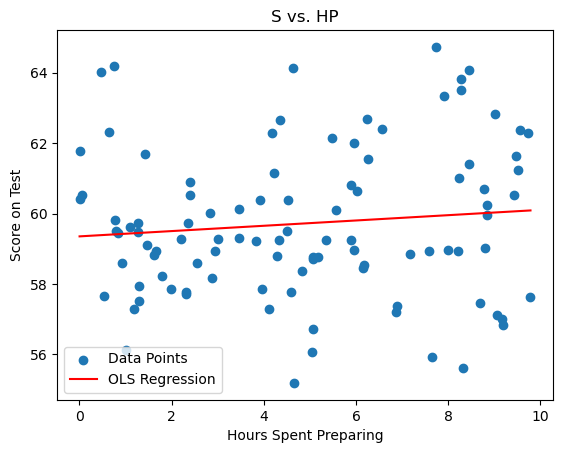

In [27]:
# First Prediction just using Hours Prepped (HP)
X_1 = sm.add_constant(df['HP'])
model_1 = sm.OLS(df['S'], X_1).fit()

# Constants
beta_0 = model_1.params.iloc[0]
beta_HP = model_1.params.iloc[1]
print(f'Score vs. Hours Prepped:\n Beta_0 = {beta_0}\n Beta_HP = {beta_HP}')

# Graph
plt.scatter(HP, S, label='Data Points')
t1 = np.linspace(HP.min(), HP.max(), 100)
t_1 = sm.add_constant(t1)
y_1 = model_1.predict(t_1)
plt.plot(t1, y_1, c='r', label='OLS Regression')
plt.xlabel('Hours Spent Preparing')
plt.ylabel('Score on Test')
plt.title('S vs. HP')
plt.legend()
print()

#model_1.summary()

Just by looking at the above graph we see that there appears to be little correlationg between HP and S. Indeed, the coefficient for HP, the slope of the line, is fairly close to 0, showing at most a fairly weak positive correlation between the two variables. 

In the next cell we will see that $\beta_{HP}$ will get larger upon accounting/controlling for the additional variable Hours of Sleep (HS).

<div class="alert alert-block alert-info">
<b>Comment:</b> It's worth saying that I did a lot of tinkering with the variable initilizations to get this specific example (I wonder if you can figure out why it happened when I put the coeffcients for MM and HP very close to eachother in S ???), but it's not the only one. I could have easily shown examples for where the relationship was even negative, but thought a weak positive relationship just exemplified the point the best. 
</div>

Here's the second regression now using both HP and HS. I tried to give a graph of the 'fitting' plane but the static graph doesn't really show the best angle. I did try to get an interactive graph working so uncomment that part if you want to try it out (for me it felt like it was gonna break my computer).

Score vs. Hours Prepped, Hours Slept:
 Beta_0 = 55.710971740231244
 Beta_HP = 4.2868832776574175
 Beta_HS = 2.622964384610394


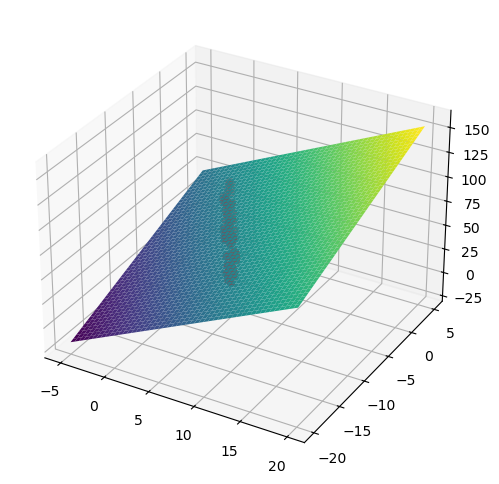

In [29]:
# Second Prediction using HP and Hours Slept (HS)
X_2 = sm.add_constant(df[['HP', 'HS']])
model_2 = sm.OLS(df['S'], X_2).fit()

# Constants
beta_02 = model_2.params.iloc[0]
beta_HP2 = model_2.params.iloc[1]
beta_HS = model_2.params.iloc[2]
print(f'Score vs. Hours Prepped, Hours Slept:\n Beta_0 = {beta_02}\n Beta_HP = {beta_HP2}\n Beta_HS = {beta_HS}')

# Static Graph
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
x = np.linspace(-5, 20, 1000)
y = np.linspace(-20, 5, 1000)
X, Y = np.meshgrid(x, y)
Z = beta_02 + beta_HP2 * X + beta_HS * Y
ax.plot_surface(X, Y, Z, cmap='viridis', alpha=1)
ax.scatter(HP, HS, S, c='r')

# Interactive Graph (felt like it was gonna crash my computer)
#figure = go.Figure(data=[go.Surface(z=Z, x=X, y=Y, opacity=0.6, 
#colorbar={'title':'Score'})])
#figure.add_trace(go.Scatter3d(x=HP, y=HS, z=S, mode='markers', name='Data Points'))
#figure.update_layout(title='S vs HP and HS', 
#scene={'xaxis':{'title':'HP'}, 'yaxis':{'title':'HS'}, 'zaxis':{'title':'S'}})
#figure.show()

#model_2.summary()

Clearly there was a massive increase in the value of $\beta_{HP}$ from the first example to the second. This means that controlling for hours slept determined a much more positive relationship between HP and S. 

To finish things off, let's see how the model looks when we account for the final variable, Material Memorized.

In [32]:
# Final Prediction Controlling for All Variables
X = sm.add_constant(df[['HP', 'MM', 'HS']])
model_3 = sm.OLS(df['S'], X).fit()

# Constants
beta_03 = model_3.params.iloc[0]
beta_HP3 = model_3.params.iloc[1]
beta_HS2 = model_3.params.iloc[2]
beta_MM = model_3.params.iloc[3]
print(f'Score vs. Hours Prepped, Hours Slept, Material Memorized:\n Beta_0 = {beta_03}\n Beta_HP = {beta_HP3}\n Beta_HS = {beta_HS2}\n Beta_MM = {beta_MM}')


Score vs. Hours Prepped, Hours Slept, Material Memorized:
 Beta_0 = 51.05005508918877
 Beta_HP = -0.09648072093570015
 Beta_HS = 3.234020799245876
 Beta_MM = 2.926389557936943


Now the coefficients are very close to the preset values we had in the initilization of S, showing that our model is likely doing the right thing. Although $\beta_{HP}$ decreased in magnitude from the last example, notice that it still is greater in magnitude than the first example, and $\beta_{HS}$ is also greater than its previous value. So clearly we got coefficient increases all around. It's also possible to still have $\beta_{HP}$ be positive at this point, while retaining some of the same suppression behavior in the previous examples by setting the coefficients for HP and MM in <br>`S = 0*HP + 3.25*MM + 3*HS + np.random.rand(100)*2 + 50` close to eachother, e.g. 0 --> 2.9, 3.25 --> 3.

Overall, as I said before this is a pretty contrived example and I don't even know if it makes any sense, but the bottom line is that taken from an abstract perspective we can find a data set with variables such that adding in a new variable makes the value of a coefficient increase. 

## Challange
My challenge to you is to add in some irrelevant variables and see if you can make them decrease the coefficients of the other variables

# References
1. https://en.wikipedia.org/wiki/Suppressor_variable
1. https://www.datarobot.com/blog/multiple-regression-using-statsmodels/
1. https://www.ibm.com/docs/en/watson-studio-local/1.2.3?topic=notebooks-markdown-jupyter-cheatsheet
1. https://plotly.com/
1. Google AI Overview
